In [1]:
'''Build and validate end-to-end deployment-ready machine learning pipelines, incorporating automated preprocessing,
 inference, monitoring, and continuous integration/continuous deployment (CI/CD) workflows.'''

'Build and validate end-to-end deployment-ready machine learning pipelines, incorporating automated preprocessing,\n inference, monitoring, and continuous integration/continuous deployment (CI/CD) workflows.'

In [2]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [3]:
# load dataset
df = pd.read_csv('global_pharmacy_sales_data.csv')
df.head()


,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag
0,2025-10-12,2025,10,12,Middle East,UAE,Chronic,Amlodipine,0-12,328,45.38,4774,466,0
1,2020-09-15,2020,9,15,South Asia,India,Chronic,Amlodipine,26-45,371,75.49,4584,181,1
2,2020-02-26,2020,2,26,Middle East,UAE,Vitamin,Vitamin C,0-12,948,22.51,3934,556,1
3,2025-11-09,2025,11,9,South Asia,Sri Lanka,Chronic,Amlodipine,0-12,275,63.29,4544,330,0
4,2022-04-04,2022,4,4,South America,Argentina,Chronic,Amlodipine,26-45,563,44.28,4284,590,0


In [4]:
# prepare features and split data
features = ['month', 'region', 'category', 'medicine', 'age_group', 'unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag']
X = df[features]
y = df['units_sold']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [5]:
# build automated preprocessing and model pipeline
num_cols = ['month', 'unit_price', 'stock_level', 'expiry_days_remaining']
cat_cols = ['region', 'category', 'medicine', 'age_group', 'covid_flag']

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
])

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(n_estimators=30, max_depth=10, random_state=42))
])


In [6]:
# train and evaluate pipeline
pipeline.fit(X_train.iloc[:30000], y_train.iloc[:30000])
y_pred = pipeline.predict(X_test.iloc[:5000])
print('MAE:', mean_absolute_error(y_test.iloc[:5000], y_pred))
print('RMSE:', np.sqrt(mean_squared_error(y_test.iloc[:5000], y_pred)))
print('R2 Score:', r2_score(y_test.iloc[:5000], y_pred))


MAE: 64.59379056802199
RMSE: 85.87268879167014
R2 Score: 0.9405292061319194


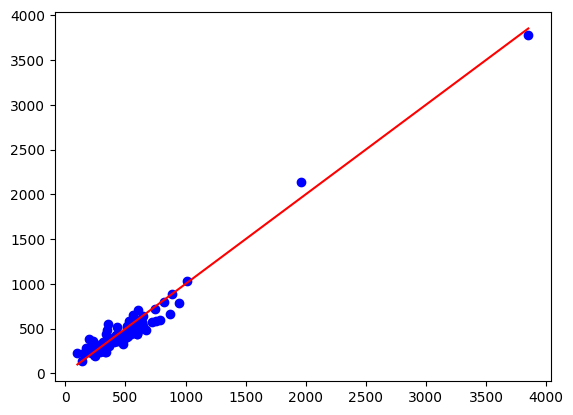

In [7]:
# plot actual vs predicted values
plt.scatter(y_test.iloc[:100], y_pred[:100], color='blue')
plt.plot([y_test.iloc[:100].min(), y_test.iloc[:100].max()], [y_test.iloc[:100].min(), y_test.iloc[:100].max()], color='red')
plt.show()


In [8]:
# save pipeline artifact for deployment
joblib.dump(pipeline, 'sales_pipeline.joblib')
print('Pipeline saved successfully')


Pipeline saved successfully


In [9]:
# run automated batch inference
loaded_model = joblib.load('sales_pipeline.joblib')
sample_inference = X_test.iloc[:5].copy()
sample_inference['predicted_units_sold'] = loaded_model.predict(sample_inference)
sample_inference


,month,region,category,medicine,age_group,unit_price,stock_level,expiry_days_remaining,covid_flag,predicted_units_sold
168929,11,Middle East,Antibiotic,Azithromycin,46-65,53.07,4601,342,0,298.323260
20669,7,Oceania,Antipyretic,Ibuprofen,65+,79.53,4696,524,0,287.993585
4526,5,Europe,Vitamin,Vitamin C,26-45,49.82,4352,677,0,528.464794
171149,9,East Asia,Vitamin,Vitamin C,13-25,64.46,4603,198,1,381.211647
65989,7,North America,Antipyretic,Paracetamol,13-25,87.59,4515,224,0,355.485110


In [10]:
# monitor data drift and performance
baseline_mean = y_train.iloc[:30000].mean()
current_mean = y_pred.mean()
drift_pct = abs(current_mean - baseline_mean) / baseline_mean * 100
print(f'Baseline Mean: {baseline_mean:.2f}')
print(f'Prediction Mean: {current_mean:.2f}')
print(f'Drift Percentage: {drift_pct:.2f}%')
if drift_pct > 10:
    print('Alert: Significant drift detected')
else:
    print('Status: Model operating within normal drift threshold')


Baseline Mean: 448.40
Prediction Mean: 452.54
Drift Percentage: 0.92%
Status: Model operating within normal drift threshold


In [11]:
# validate cicd automated test suite
def test_pipeline():
    test_sample = X_test.iloc[:10]
    preds = loaded_model.predict(test_sample)
    assert len(preds) == len(test_sample), 'Inference output length mismatch'
    assert not np.isnan(preds).any(), 'Predictions contain null values'
    assert (preds >= 0).all(), 'Negative sales predictions found'
    score = loaded_model.score(X_test.iloc[:5000], y_test.iloc[:5000])
    assert score > 0.8, f'Model R2 score below threshold: {score}'
    return 'All CI/CD tests passed successfully'

print(test_pipeline())


All CI/CD tests passed successfully
